# JS07 - Klasterisasi | Lab 1
## K-Means pada Dataset Iris

**Nama:** Gunawan Wibisono
**NIM:** 244107020132
**Kelas:** TI-2H

> Modul: [JTI - Modul Praktikum Pembelajaran Mesin - JS07 Klasterisasi](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-mah/js07-klasterisasi)

## Tujuan
1. Memahami konsep klasterisasi dengan algoritma K-Means.
2. Mampu membangun model K-Means pada data tanpa label.
3. Mampu mengevaluasi model dengan SSE dan menentukan jumlah cluster optimal dengan *elbow method*.

## Pengantar
Dataset **Iris** berisi 150 data bunga Iris dengan 4 fitur numerik (panjang & lebar sepal dan petal).
Dataset ini sebenarnya **sudah berlabel** (3 spesies), tetapi pada praktikum ini label tersebut
**diabaikan** — kita seolah-olah hanya memiliki fitur `X` tanpa label `Y`, sehingga kasusnya
relevan untuk klasterisasi.

## Langkah 1 - Import Library

In [1]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

%matplotlib inline

## Langkah 2 - Load dan Inspeksi Data

Dataset `Iris.csv` diletakkan satu folder dengan notebook ini.

In [2]:
df = pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


**Interpretasi:** data terdiri dari **150 baris** dan **6 kolom** (`Id`, 4 fitur numerik, dan `Species`).
Seluruh kolom memiliki 150 nilai non-null, artinya **tidak ada missing value**.

## Langkah 3 - Seleksi Fitur

Kita hanya membutuhkan fitur untuk proses klasterisasi, sehingga kolom `Id` dan `Species`
(label) dipisahkan dengan *slicing*.

In [4]:
# Features Selection
X = df.iloc[:, 1:-1]  # slice the features (Id dan Species dibuang)
y = df.iloc[:, -1]    # this is the labels (we don't need it for clustering)

print(X.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


Index slicing `[:, 1:-1]` berarti: **semua baris**, kolom indeks 1 sampai sebelum kolom terakhir.
Kolom `Id` (indeks 0) dan `Species` (indeks terakhir) tidak ikut terambil.

## Langkah 4 - Plotting

Visualisasi sebaran data memakai 2 fitur: `SepalLengthCm` dan `SepalWidthCm`.

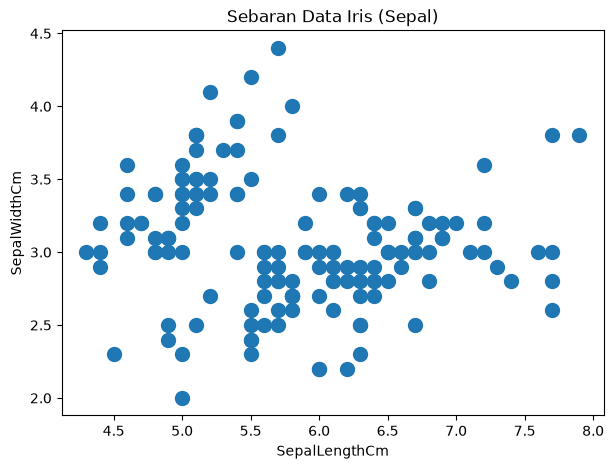

In [5]:
# Make a scatterplot using SepalLengthCm and SepalWidthCm
plt.figure(figsize=(7, 5))
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.title('Sebaran Data Iris (Sepal)')
plt.show()

Secara visual terlihat ada **dua kelompok** data: kelompok dengan sepal pendek dan kelompok dengan
sepal lebih panjang. Karena itu, model pertama akan dibangun dengan asumsi `k = 2`
(walaupun dari label asli sebenarnya ada 3 spesies).

## Langkah 5 - Membuat Model K-Means (k = 2)

`fit_predict()` melakukan dua hal sekaligus: **melatih** model (mencari centroid) dan
**memprediksi** label cluster tiap data.

> `random_state=42` dan `n_init=10` ditambahkan agar hasil dapat direproduksi.
> Tanpa `random_state`, posisi centroid awal dipilih acak sehingga hasil tiap *run* bisa berbeda.

In [6]:
# Build a K-Means Model
# Berdasarkan inspeksi visual pada scatterplot, diasumsikan data punya 2 cluster
cl_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)

print('Label cluster tiap data (10 data pertama):', y_kmeans[:10])

Label cluster tiap data (10 data pertama): [1 1 1 1 1 1 1 1 1 1]


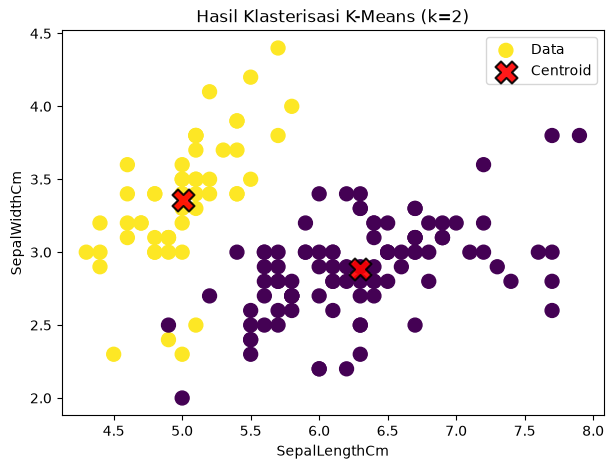

In [7]:
# Plot the clustering result
plt.figure(figsize=(7, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans, label='Data')

# Plot the centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, alpha=0.9, marker='X',
            edgecolor='black', linewidth=1.5, zorder=10, label='Centroid')
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.title('Hasil Klasterisasi K-Means (k=2)')
plt.legend()
plt.show()

Titik **merah (X)** adalah centroid hasil akhir. K-Means memisahkan data dengan **garis linear**
(decision boundary tegak lurus di antara kedua centroid), sehingga pembagiannya cenderung "lurus"
walaupun sebaran aslinya sedikit melengkung.

## Langkah 6 - Evaluasi Model (SSE)

Metrik internal yang paling sederhana untuk K-Means adalah **SSE** (*Sum of Squared Error*),
yaitu jumlah kuadrat jarak setiap data ke centroid cluster-nya. Nilai ini tersedia pada
properti `inertia_`.

In [8]:
# Print SSE value
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733906


SSE bersifat **semakin kecil semakin baik**, tetapi nilainya **tidak bisa dibandingkan antar nilai k**
(lihat Langkah 7). SSE hanya berguna untuk membandingkan beberapa inisialisasi pada `k` yang sama.

## Langkah 7 - Menentukan $k$ terbaik dengan Elbow Method

Cara kerja *elbow method*:
1. Tentukan rentang `k` yang akan dievaluasi.
2. Hitung SSE untuk setiap `k`.
3. Buat *lineplot* SSE terhadap `k`, lalu cari titik "siku" (*elbow*).

In [9]:
# Find the best k using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 9
K = range(1, 10)

# Find the SSE value for each k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Show the SSE table
pd.DataFrame({'k': list(K), 'SSE': sse})

,k,SSE
0,1,680.824400
1,2,152.368706
2,3,78.940841
3,4,57.317873
4,5,46.535582
5,6,38.930963
6,7,34.360209
7,8,30.023416
8,9,28.145502


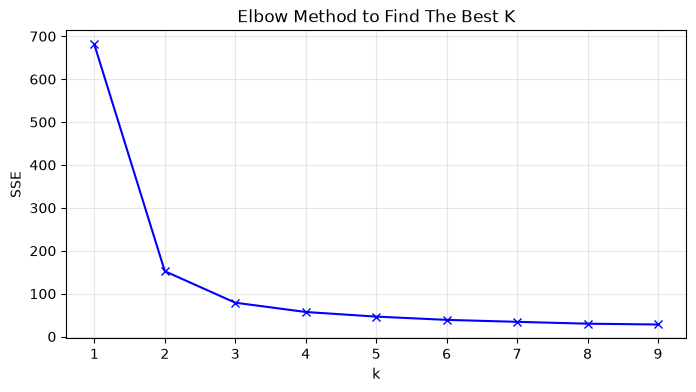

In [10]:
# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method to Find The Best K')
plt.xticks(list(K))
plt.grid(alpha=.3)
plt.show()

In [11]:
# Berapa persen SSE turun di setiap penambahan k?
turun = [(sse[i-1] - sse[i]) / sse[i-1] * 100 for i in range(1, len(sse))]
pd.DataFrame({'k': list(K)[1:], 'penurunan SSE (%)': np.round(turun, 2)})

,k,penurunan SSE (%)
0,2,77.62
1,3,48.19
2,4,27.39
3,5,18.81
4,6,16.34
5,7,11.74
6,8,12.62
7,9,6.25


**Analisis:** penurunan SSE terbesar terjadi pada `k=1 -> 2` dan `k=2 -> 3`
(lihat tabel persentase). Setelah `k=3`, penurunan SSE mulai **melandai** dan
selisihnya makin kecil. Titik siku inilah yang disebut *elbow*.

**Kesimpulan: `k = 3` adalah jumlah cluster terbaik.**

Ingat: jumlah cluster terbaik **bukan** yang SSE-nya paling rendah. SSE selalu mengecil
seiring bertambahnya `k`, karena cluster makin sempit dan anggotanya makin sedikit.
Yang dicari adalah titik di mana penurunan tajam berubah menjadi penurunan yang stabil.

## Langkah 8 - Model Final dengan $k = 3$

Model final dibangun memakai `k=3` sesuai hasil *elbow method*.

SSE model final (k=3): 78.94084142614601


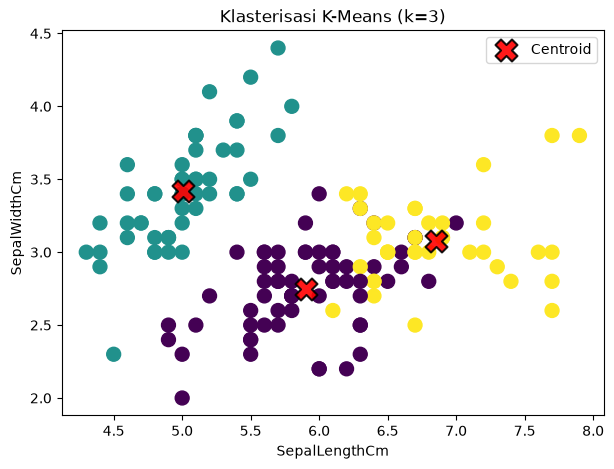

In [12]:
# Final model with k = 3
cl_final = KMeans(n_clusters=3, random_state=42, n_init=10)
y_final = cl_final.fit_predict(X)

print(f'SSE model final (k=3): {cl_final.inertia_}')

plt.figure(figsize=(7, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_final, cmap='viridis')
plt.scatter(cl_final.cluster_centers_[:, 0], cl_final.cluster_centers_[:, 1],
            c='red', s=250, alpha=0.9, marker='X', edgecolor='black',
            linewidth=1.5, zorder=10, label='Centroid')
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.title('Klasterisasi K-Means (k=3)')
plt.legend()
plt.show()

In [13]:
# Sebaran anggota tiap cluster
jumlah = pd.Series(y_final, name='cluster').value_counts().sort_index()
print(jumlah.to_string())

cluster
0    62
1    50
2    38


## Langkah 9 (Tambahan) - Validasi dengan Label Asli

Label `Species` tidak dipakai saat melatih model, tetapi bisa dipakai untuk **memeriksa**
apakah cluster yang terbentuk sesuai dengan spesies sebenarnya.

In [14]:
from sklearn.metrics import adjusted_rand_score

# Crosstab: cluster vs spesies asli
pd.crosstab(pd.Series(y_final, name='cluster'), y, margins=True)

Species,Iris-setosa,Iris-versicolor,Iris-virginica,All
cluster,,,,
0,0,48,14,62
1,50,0,0,50
2,0,2,36,38
All,50,50,50,150


In [15]:
print('Adjusted Rand Index (k=3):', round(adjusted_rand_score(y, y_final), 4))
print('Adjusted Rand Index (k=2):', round(adjusted_rand_score(y, y_kmeans), 4))

Adjusted Rand Index (k=3): 0.7302
Adjusted Rand Index (k=2): 0.5399


ARI bernilai 1 bila kedua partisi identik dan 0 bila sama dengan partisi acak. Nilai ARI yang
tinggi pada `k=3` menunjukkan cluster hasil K-Means hampir sama dengan pembagian spesies aslinya —
padahal model sama sekali tidak pernah melihat label.

## Kesimpulan Lab 1
1. K-Means berhasil mengelompokkan data Iris **tanpa label** hanya dengan 4 fitur numerik.
2. Asumsi awal `k=2` (dari inspeksi visual sepal) menghasilkan pemisahan yang terlalu kasar.
3. *Elbow method* menunjukkan **`k=3`** sebagai jumlah cluster optimal.
4. Cluster hasil `k=3` sangat dekat dengan 3 spesies asli (ARI tinggi), sehingga K-Means
   cocok untuk data yang **dapat dipisahkan secara linear** seperti Iris.